# 10 - Trực quan hóa cụm: khen gì, chê gì

Notebook này giúp trả lời:
- Mỗi cụm khách sạn được khách **khen nhiều nhất điều gì**?
- Mỗi cụm khách sạn bị khách **chê nhiều nhất điều gì**?
- Aspect nào làm từng cụm khác nhau rõ nhất?

Chạy sau khi đã chạy `src/08_compare_and_train_clustering.py`.


## 1. Khai báo thư viện và đường dẫn

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

CURRENT_DIR = Path.cwd()
NOTEBOOK_DIR_NAMES = {
    "notebook", "notebooks", "notebook_colab", "notebooks_colab",
    "notebooke_colab", "notebooks_report", "notebook_report"
}

if CURRENT_DIR.name in NOTEBOOK_DIR_NAMES:
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Nếu notebook nhận sai đường dẫn, sửa dòng dưới:
# PROJECT_ROOT = Path(r"D:\ĐỒ_ÁN_CƠ_SỞ_V2")

TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Table dir:", TABLE_DIR)
print("Table dir exists:", TABLE_DIR.exists())


Project root: d:\ĐỒ_ÁN_CƠ_SỞ_V2
Table dir: d:\ĐỒ_ÁN_CƠ_SỞ_V2\outputs\tables
Table dir exists: True


## 2. Đọc kết quả phân cụm

In [2]:
results_path = TABLE_DIR / "hotel_cluster_results.csv"
summary_path = TABLE_DIR / "hotel_cluster_summary.csv"
config_path = TABLE_DIR / "hotel_clustering_final_config.csv"

if not results_path.exists():
    raise FileNotFoundError(f"Không tìm thấy {results_path}. Hãy chạy file 08 trước.")

results_df = pd.read_csv(results_path)
summary_df = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame()
config_df = pd.read_csv(config_path) if config_path.exists() else pd.DataFrame()

print("results_df:", results_df.shape)
print("summary_df:", summary_df.shape)
print("config_df:", config_df.shape)

if not config_df.empty:
    display(config_df)

display(results_df.head())


results_df: (1998, 96)
summary_df: (3, 14)
config_df: (1, 11)


,algorithm,n_clusters,min_reviews_per_hotel,feature_mode,scaler,pca_components_for_clustering,pca_explained_variance,num_features_before_pca,silhouette_score,davies_bouldin_index,calinski_harabasz_index
0,KMeans,3,3,no_text_no_group_no_topic,RobustScaler,8,0.740499,52,0.370077,1.215927,791.188342


,hotel_id,amenities,avg_char_count,avg_review_rating,avg_sentiment_score,avg_word_count,checkin_mention_ratio,checkin_negative_ratio,checkin_positive_ratio,cleanliness,cleanliness_mention_ratio,cleanliness_negative_ratio,cleanliness_positive_ratio,comfort,country_diversity,couple_ratio,facilities_mention_ratio,facilities_negative_ratio,facilities_positive_ratio,family_ratio,feature_built_at,food_mention_ratio,food_negative_ratio,food_positive_ratio,free_wifi,group_ratio,hotel_feature_status,hotel_name,hotel_rating,hotel_rating_group,location,location_mention_ratio,location_negative_ratio,location_positive_ratio,max_review_rating,max_word_count,min_review_rating,negative_ratio,negative_review_count,neutral_ratio,neutral_review_count,noise_mention_ratio,noise_negative_ratio,noise_positive_ratio,num_customer_countries,num_reviews,num_reviews_imported_sample,num_reviews_in_file,num_reviews_with_text_in_file,other_ratio,positive_ratio,positive_review_count,price_mention_ratio,price_negative_ratio,price_positive_ratio,province_id,province_name,room_mention_ratio,room_negative_ratio,room_positive_ratio,service_mention_ratio,service_negative_ratio,service_positive_ratio,service_staff,short_review_ratio,solo_ratio,source_file,std_review_rating,top_country_ratio,topic_0_ratio,topic_10_ratio,topic_11_ratio,topic_1_ratio,topic_2_ratio,topic_3_ratio,topic_4_ratio,topic_5_ratio,topic_6_ratio,topic_7_ratio,topic_8_ratio,topic_9_ratio,total_rating,unknown_ratio,updated_at,valid_embedding_ratio,value_for_money,wifi_mention_ratio,wifi_negative_ratio,wifi_positive_ratio,cluster,cluster_algorithm,cluster_n_clusters,cluster_updated_at,final_cluster,pca_x,pca_y
0,70e7270e63138fa24635a7d19dc7ace5,9.6,924.2,8.9,0.7,161.8,0.1,0.1,0.0,9.7,0.4,0.4,0.0,9.6,2.025326,0.0,0.6,0.1,0.6,0.0,2026-05-14 09:28:35.221,0.6,0.2,0.5,9.4,0.1,built_from_existing_e5_aspects,Homestay Khoa Chaudoc,9.6,high,9.7,0.7,0.1,0.7,10.0,285.0,7.0,0.0,0.0,0.3,3.0,0.4,0.4,0.0,8.0,10.0,10,613,500,0.5,0.7,7.0,0.1,0.1,0.1,an-giang,An Giang,0.6,0.4,0.4,0.7,0.0,0.7,9.9,0.0,0.4,D:\ĐỒ_ÁN_CƠ_SỞ_V2\raw_data\raw_data\an-giang\h...,1.300000,0.2,0.0,0.0,0.4,0.3,0.2,0.0,0.0,0.0,0.1,0.0,0.0,0.0,612,0.0,2026-05-14 13:50:03.336,1.0,9.8,0.0,0.0,0.0,2,KMeans,3.0,2026-05-14 13:50:03.336,2.0,6.226760,0.878126
1,aab5009f60f50afa137aa6986108177f,9.1,758.6,6.6,0.1,145.7,0.7,0.6,0.4,9.3,0.5,0.4,0.1,9.3,1.643418,0.3,0.8,0.2,0.7,0.0,2026-05-14 09:28:35.221,0.2,0.2,0.0,9.5,0.3,built_from_existing_e5_aspects,Kim Ngân Motel,9.0,high,8.8,0.9,0.3,0.7,10.0,213.0,1.0,0.3,3.0,0.3,3.0,0.3,0.2,0.1,6.0,10.0,10,756,362,0.1,0.4,4.0,0.1,0.1,0.0,an-giang,An Giang,0.5,0.5,0.2,0.6,0.2,0.5,9.4,0.0,0.3,D:\ĐỒ_ÁN_CƠ_SỞ_V2\raw_data\raw_data\an-giang\k...,3.168596,0.3,0.0,0.0,0.1,0.3,0.1,0.0,0.3,0.2,0.0,0.0,0.0,0.0,755,0.0,2026-05-14 13:50:03.336,1.0,9.5,0.3,0.3,0.0,1,KMeans,3.0,2026-05-14 13:50:03.336,1.0,-0.289712,2.357383
2,4eacfb930a4bed13d87c4de3f21189fb,9.0,810.5,6.7,0.1,137.9,0.4,0.2,0.2,9.5,0.4,0.4,0.0,9.4,1.748067,0.8,0.7,0.3,0.5,0.0,2026-05-14 09:28:35.221,0.5,0.4,0.1,9.4,0.1,built_from_existing_e5_aspects,Paris Hotel Châu Đốc,9.0,high,9.6,1.0,0.2,1.0,10.0,258.0,1.0,0.3,3.0,0.3,3.0,0.2,0.2,0.0,6.0,10.0,10,410,285,0.1,0.4,4.0,0.0,0.0,0.0,an-giang,An Giang,0.7,0.6,0.4,0.9,0.4,0.7,9.6,0.0,0.0,D:\ĐỒ_ÁN_CƠ_SỞ_V2\raw_data\raw_data\an-giang\p...,2.685144,0.2,0.0,0.2,0.1,0.2,0.1,0.0,0.0,0.4,0.0,0.0,0.0,0.0,407,0.0,2026-05-14 13:50:03.336,1.0,9.4,0.1,0.0,0.1,1,KMeans,3.0,2026-05-14 13:50:03.336,1.0,0.373902,3.368535
3,8a7d23fbad89e0d68a6f7066c8b3a254,8.8,949.0,6.8,0.1,161.0,0.8,0.8,0.1,9.1,0.4,0.3,0.1,9.3,1.359237,0.3,0.9,0.1,0.8,0.0,2026-05-14 09:28:35.221,0.7,0.5,0.4,8.0,0.1,built_from_existing_e5_aspects,Victoria Chau Doc Hotel,8.9,high,9.5,0.9,0.3,0.8,10.0,277.0,1.0,0.3,3.0,0.3,3.0,0.1,0.1,0.0,5.0,10.0,10,360,237,0.5,0.4,4.0,0.1,0.1,0.0,an-giang,An Giang,1.0,0.6,0.6,0.1,0.1,0.1,9.4,0.0,0.1,D:\ĐỒ_ÁN_CƠ_SỞ_V2\raw_data\raw_data\an-giang\v...,3.026549,0.5,0.0,0.0,0.0,0.6,0.0,0.0,0.1,0.3,0.0,0.0,0.0,0.0,360,0.0,2026-05-14 13:50:03.

## 3. Tìm các cột aspect tích cực / tiêu cực / mention

In [3]:
positive_cols = sorted([c for c in results_df.columns if c.endswith("_positive_ratio")])
negative_cols = sorted([c for c in results_df.columns if c.endswith("_negative_ratio")])
mention_cols = sorted([c for c in results_df.columns if c.endswith("_mention_ratio")])

print("Positive aspect columns:", len(positive_cols))
print(positive_cols)
print("\nNegative aspect columns:", len(negative_cols))
print(negative_cols)
print("\nMention aspect columns:", len(mention_cols))
print(mention_cols)

if not positive_cols or not negative_cols:
    raise ValueError("Không tìm thấy cột aspect positive/negative. Kiểm tra file 07 đã build aspect features chưa.")


Positive aspect columns: 10
['checkin_positive_ratio', 'cleanliness_positive_ratio', 'facilities_positive_ratio', 'food_positive_ratio', 'location_positive_ratio', 'noise_positive_ratio', 'price_positive_ratio', 'room_positive_ratio', 'service_positive_ratio', 'wifi_positive_ratio']

Negative aspect columns: 10
['checkin_negative_ratio', 'cleanliness_negative_ratio', 'facilities_negative_ratio', 'food_negative_ratio', 'location_negative_ratio', 'noise_negative_ratio', 'price_negative_ratio', 'room_negative_ratio', 'service_negative_ratio', 'wifi_negative_ratio']

Mention aspect columns: 10
['checkin_mention_ratio', 'cleanliness_mention_ratio', 'facilities_mention_ratio', 'food_mention_ratio', 'location_mention_ratio', 'noise_mention_ratio', 'price_mention_ratio', 'room_mention_ratio', 'service_mention_ratio', 'wifi_mention_ratio']


## 4. Tính trung bình aspect theo cụm

In [4]:
aspect_cols = positive_cols + negative_cols + mention_cols

cluster_aspect_mean = (
    results_df
    .groupby("cluster")[aspect_cols]
    .mean()
    .reset_index()
)

display(cluster_aspect_mean)

# output_path = TABLE_DIR / "cluster_aspect_mean_positive_negative.csv"
# cluster_aspect_mean.to_csv(output_path, index=False, encoding="utf-8-sig")
# print("Saved:", output_path)


,cluster,checkin_positive_ratio,cleanliness_positive_ratio,facilities_positive_ratio,food_positive_ratio,location_positive_ratio,noise_positive_ratio,price_positive_ratio,room_positive_ratio,service_positive_ratio,wifi_positive_ratio,checkin_negative_ratio,cleanliness_negative_ratio,facilities_negative_ratio,food_negative_ratio,location_negative_ratio,noise_negative_ratio,price_negative_ratio,room_negative_ratio,service_negative_ratio,wifi_negative_ratio,checkin_mention_ratio,cleanliness_mention_ratio,facilities_mention_ratio,food_mention_ratio,location_mention_ratio,noise_mention_ratio,price_mention_ratio,room_mention_ratio,service_mention_ratio,wifi_mention_ratio
0,0,0.415549,0.306845,0.195630,0.199679,0.319352,0.151147,0.121802,0.216704,0.271350,0.076350,0.428957,0.436267,0.072945,0.127035,0.085751,0.151970,0.055077,0.396625,0.107933,0.202030,0.688915,0.618889,0.254450,0.305495,0.382223,0.271246,0.170147,0.536134,0.362391,0.260072
1,1,0.364600,0.174661,0.444010,0.263056,0.536197,0.072559,0.045692,0.440324,0.408294,0.032637,0.494443,0.389602,0.240416,0.199069,0.199441,0.141186,0.028429,0.593159,0.167298,0.120066,0.662212,0.491575,0.562366,0.413377,0.628441,0.203169,0.071549,0.772711,0.516183,0.148047
2,2,0.371396,0.273283,0.372491,0.335160,0.427969,0.091691,0.066343,0.324140,0.500425,0.021873,0.276490,0.333597,0.072299,0.174491,0.091171,0.169655,0.058641,0.257853,0.087091,0.176558,0.539329,0.510698,0.409525,0.454738,0.480134,0.239407,0.120430,0.490630,0.550280,0.190883


## 5. Top aspect được khách khen trong từng cụm

In [5]:
def clean_aspect_name(col):
    return (
        col.replace("_positive_ratio", "")
           .replace("_negative_ratio", "")
           .replace("_mention_ratio", "")
    )

top_n = 5
positive_rows = []

for _, row in cluster_aspect_mean.iterrows():
    cluster = row["cluster"]
    values = row[positive_cols].sort_values(ascending=False).head(top_n)
    for col, value in values.items():
        positive_rows.append({
            "cluster": cluster,
            "aspect": clean_aspect_name(col),
            "positive_ratio_mean": value,
        })

top_positive_df = pd.DataFrame(positive_rows)
display(top_positive_df)

# output_path = TABLE_DIR / "cluster_top_positive_aspects.csv"
# top_positive_df.to_csv(output_path, index=False, encoding="utf-8-sig")
# print("Saved:", output_path)


,cluster,aspect,positive_ratio_mean
0,0.0,checkin,0.415549
1,0.0,location,0.319352
2,0.0,cleanliness,0.306845
3,0.0,service,0.271350
4,0.0,room,0.216704
5,1.0,location,0.536197
6,1.0,facilities,0.444010
7,1.0,room,0.440324
8,1.0,service,0.408294
9,1.0,checkin,0.364600


## 6. Biểu đồ: mỗi cụm được khen gì nhiều nhất

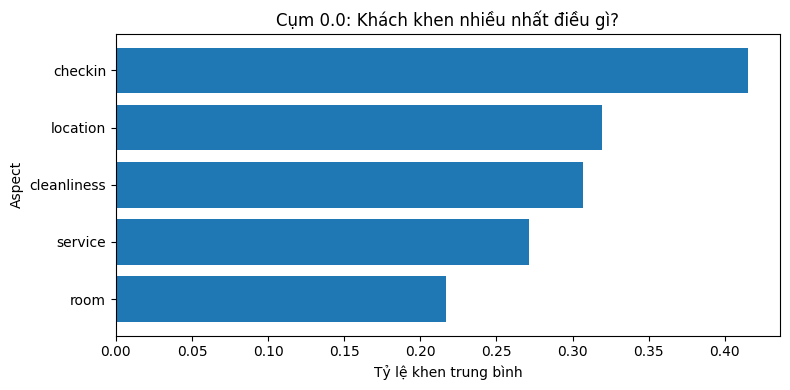

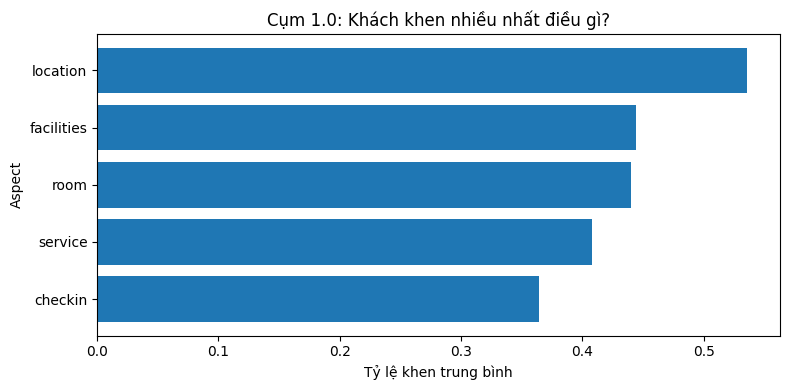

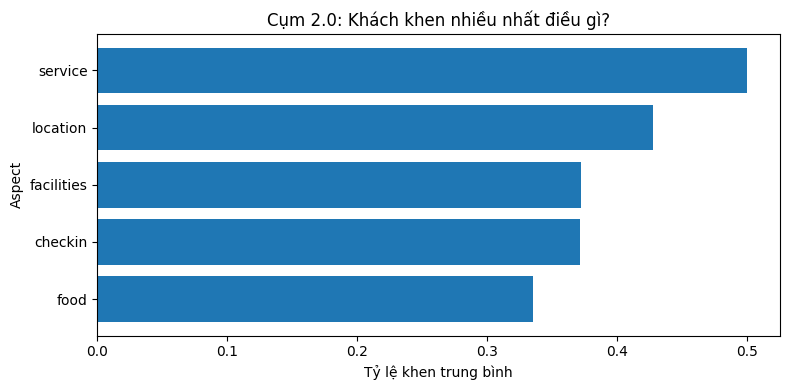

In [6]:
for cluster in sorted(top_positive_df["cluster"].unique()):
    data = top_positive_df[top_positive_df["cluster"] == cluster].sort_values("positive_ratio_mean")

    plt.figure(figsize=(8, 4))
    plt.barh(data["aspect"], data["positive_ratio_mean"])
    plt.xlabel("Tỷ lệ khen trung bình")
    plt.ylabel("Aspect")
    plt.title(f"Cụm {cluster}: Khách khen nhiều nhất điều gì?")
    plt.tight_layout()
    plt.show()


## 7. Top aspect bị khách chê trong từng cụm

In [7]:
negative_rows = []

for _, row in cluster_aspect_mean.iterrows():
    cluster = row["cluster"]
    values = row[negative_cols].sort_values(ascending=False).head(top_n)
    for col, value in values.items():
        negative_rows.append({
            "cluster": cluster,
            "aspect": clean_aspect_name(col),
            "negative_ratio_mean": value,
        })

top_negative_df = pd.DataFrame(negative_rows)
display(top_negative_df)

# output_path = TABLE_DIR / "cluster_top_negative_aspects.csv"
# top_negative_df.to_csv(output_path, index=False, encoding="utf-8-sig")
# print("Saved:", output_path)


,cluster,aspect,negative_ratio_mean
0,0.0,cleanliness,0.436267
1,0.0,checkin,0.428957
2,0.0,room,0.396625
3,0.0,wifi,0.202030
4,0.0,noise,0.151970
5,1.0,room,0.593159
6,1.0,checkin,0.494443
7,1.0,cleanliness,0.389602
8,1.0,facilities,0.240416
9,1.0,location,0.199441


## 8. Biểu đồ: mỗi cụm bị chê gì nhiều nhất

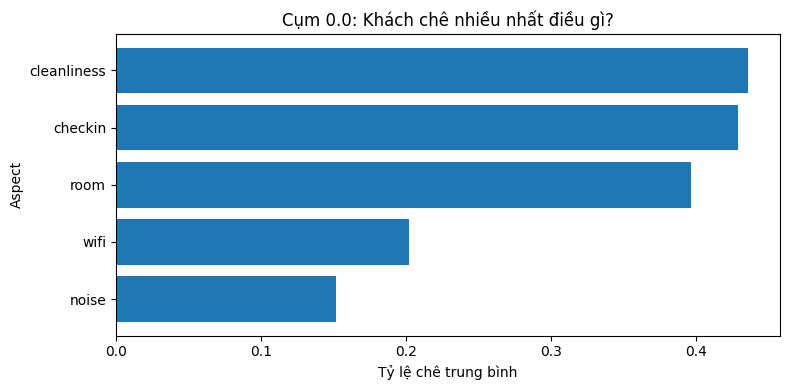

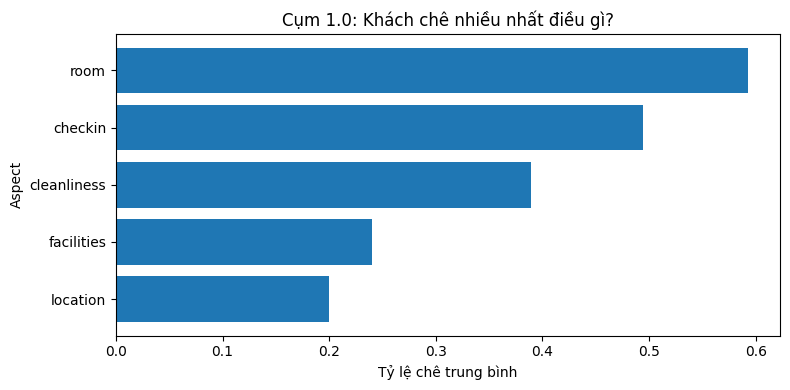

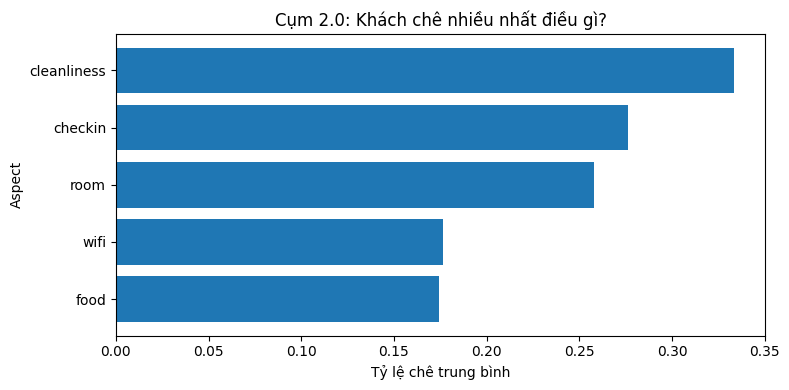

In [8]:
for cluster in sorted(top_negative_df["cluster"].unique()):
    data = top_negative_df[top_negative_df["cluster"] == cluster].sort_values("negative_ratio_mean")

    plt.figure(figsize=(8, 4))
    plt.barh(data["aspect"], data["negative_ratio_mean"])
    plt.xlabel("Tỷ lệ chê trung bình")
    plt.ylabel("Aspect")
    plt.title(f"Cụm {cluster}: Khách chê nhiều nhất điều gì?")
    plt.tight_layout()
    plt.show()


## 9. Bảng tóm tắt khen/chê để đưa vào báo cáo

In [9]:
cluster_profiles = []

for cluster in sorted(results_df["cluster"].unique()):
    pos = top_positive_df[top_positive_df["cluster"] == cluster]
    neg = top_negative_df[top_negative_df["cluster"] == cluster]

    pos_text = ", ".join([
        f"{r['aspect']} ({r['positive_ratio_mean']:.3f})"
        for _, r in pos.iterrows()
    ])

    neg_text = ", ".join([
        f"{r['aspect']} ({r['negative_ratio_mean']:.3f})"
        for _, r in neg.iterrows()
    ])

    cluster_profiles.append({
        "cluster": cluster,
        "num_hotels": int((results_df["cluster"] == cluster).sum()),
        "top_positive_aspects": pos_text,
        "top_negative_aspects": neg_text,
    })

cluster_praise_complaint_df = pd.DataFrame(cluster_profiles)
display(cluster_praise_complaint_df)

# output_path = TABLE_DIR / "cluster_praise_complaint_summary.csv"
# cluster_praise_complaint_df.to_csv(output_path, index=False, encoding="utf-8-sig")
# print("Saved:", output_path)


,cluster,num_hotels,top_positive_aspects,top_negative_aspects
0,0,257,"checkin (0.416), location (0.319), cleanliness...","cleanliness (0.436), checkin (0.429), room (0...."
1,1,1268,"location (0.536), facilities (0.444), room (0....","room (0.593), checkin (0.494), cleanliness (0...."
2,2,473,"service (0.500), location (0.428), facilities ...","cleanliness (0.334), checkin (0.276), room (0...."


## 10. Heatmap aspect được khen theo cụm

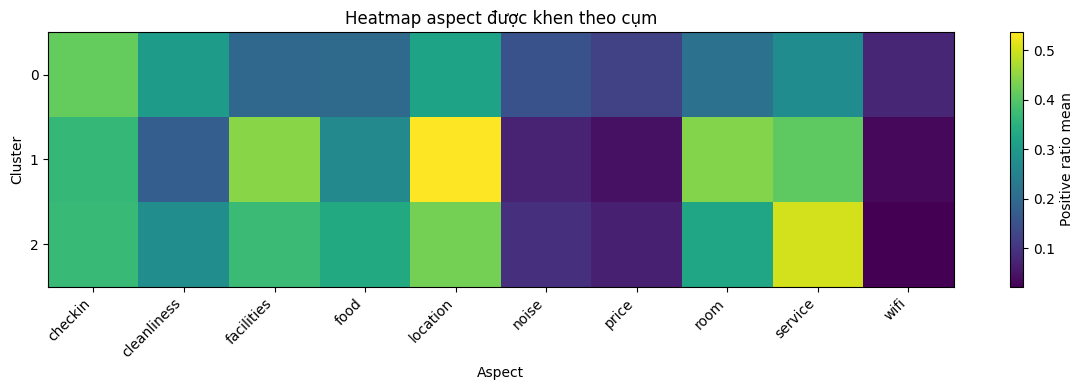

,checkin,cleanliness,facilities,food,location,noise,price,room,service,wifi
cluster,,,,,,,,,,
0,0.415549,0.306845,0.195630,0.199679,0.319352,0.151147,0.121802,0.216704,0.271350,0.076350
1,0.364600,0.174661,0.444010,0.263056,0.536197,0.072559,0.045692,0.440324,0.408294,0.032637
2,0.371396,0.273283,0.372491,0.335160,0.427969,0.091691,0.066343,0.324140,0.500425,0.021873


In [10]:
positive_heatmap = cluster_aspect_mean.set_index("cluster")[positive_cols].copy()
positive_heatmap.columns = [clean_aspect_name(c) for c in positive_heatmap.columns]

plt.figure(figsize=(12, 4))
plt.imshow(positive_heatmap.values, aspect="auto")
plt.xticks(range(len(positive_heatmap.columns)), positive_heatmap.columns, rotation=45, ha="right")
plt.yticks(range(len(positive_heatmap.index)), positive_heatmap.index)
plt.colorbar(label="Positive ratio mean")
plt.xlabel("Aspect")
plt.ylabel("Cluster")
plt.title("Heatmap aspect được khen theo cụm")
plt.tight_layout()
plt.show()

display(positive_heatmap)


## 11. Heatmap aspect bị chê theo cụm

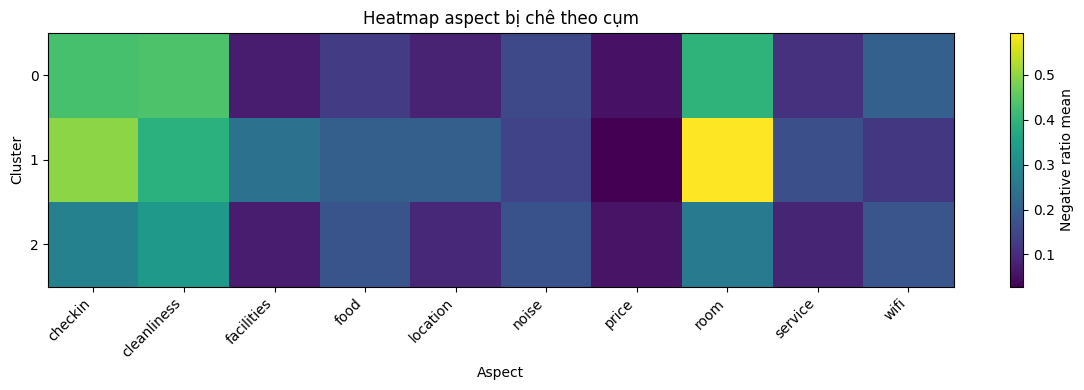

,checkin,cleanliness,facilities,food,location,noise,price,room,service,wifi
cluster,,,,,,,,,,
0,0.428957,0.436267,0.072945,0.127035,0.085751,0.151970,0.055077,0.396625,0.107933,0.202030
1,0.494443,0.389602,0.240416,0.199069,0.199441,0.141186,0.028429,0.593159,0.167298,0.120066
2,0.276490,0.333597,0.072299,0.174491,0.091171,0.169655,0.058641,0.257853,0.087091,0.176558


In [11]:
negative_heatmap = cluster_aspect_mean.set_index("cluster")[negative_cols].copy()
negative_heatmap.columns = [clean_aspect_name(c) for c in negative_heatmap.columns]

plt.figure(figsize=(12, 4))
plt.imshow(negative_heatmap.values, aspect="auto")
plt.xticks(range(len(negative_heatmap.columns)), negative_heatmap.columns, rotation=45, ha="right")
plt.yticks(range(len(negative_heatmap.index)), negative_heatmap.index)
plt.colorbar(label="Negative ratio mean")
plt.xlabel("Aspect")
plt.ylabel("Cluster")
plt.title("Heatmap aspect bị chê theo cụm")
plt.tight_layout()
plt.show()

display(negative_heatmap)


## 12. Chênh lệch khen - chê theo aspect

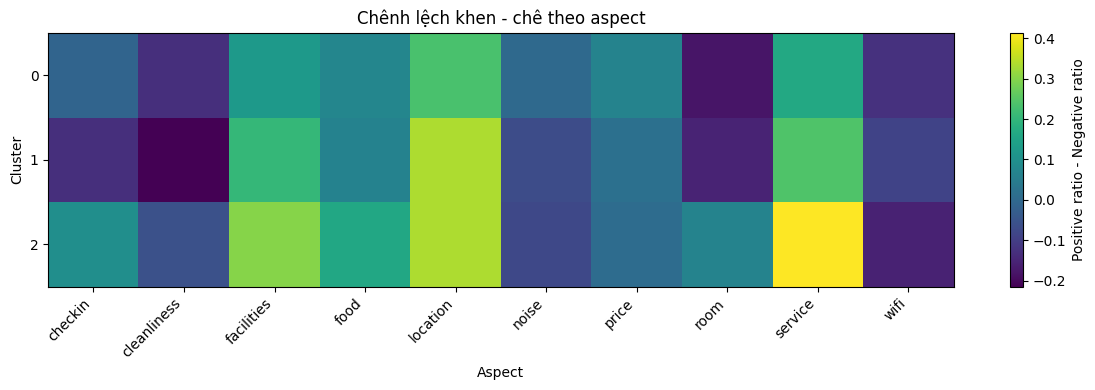

,checkin,cleanliness,facilities,food,location,noise,price,room,service,wifi
cluster,,,,,,,,,,
0,-0.013409,-0.129422,0.122685,0.072644,0.233600,-0.000823,0.066725,-0.179921,0.163416,-0.125681
1,-0.129843,-0.214941,0.203593,0.063987,0.336756,-0.068627,0.017263,-0.152835,0.240996,-0.087429
2,0.094906,-0.060313,0.300192,0.160669,0.336798,-0.077964,0.007702,0.066287,0.413334,-0.154685


In [12]:
aspect_names = sorted(set(clean_aspect_name(c) for c in positive_cols))
sentiment_balance_rows = []

for cluster in sorted(results_df["cluster"].unique()):
    out = {"cluster": cluster}
    cluster_row = cluster_aspect_mean[cluster_aspect_mean["cluster"] == cluster].iloc[0]

    for aspect in aspect_names:
        pos_col = f"{aspect}_positive_ratio"
        neg_col = f"{aspect}_negative_ratio"
        pos_value = cluster_row[pos_col] if pos_col in cluster_row.index else 0
        neg_value = cluster_row[neg_col] if neg_col in cluster_row.index else 0
        out[aspect] = pos_value - neg_value

    sentiment_balance_rows.append(out)

aspect_balance_df = pd.DataFrame(sentiment_balance_rows).set_index("cluster")

plt.figure(figsize=(12, 4))
plt.imshow(aspect_balance_df.values, aspect="auto")
plt.xticks(range(len(aspect_balance_df.columns)), aspect_balance_df.columns, rotation=45, ha="right")
plt.yticks(range(len(aspect_balance_df.index)), aspect_balance_df.index)
plt.colorbar(label="Positive ratio - Negative ratio")
plt.xlabel("Aspect")
plt.ylabel("Cluster")
plt.title("Chênh lệch khen - chê theo aspect")
plt.tight_layout()
plt.show()

display(aspect_balance_df)

# output_path = TABLE_DIR / "cluster_aspect_positive_minus_negative.csv"
# aspect_balance_df.reset_index().to_csv(output_path, index=False, encoding="utf-8-sig")
# print("Saved:", output_path)


## 13. Tự động sinh câu mô tả cụm

In [13]:
description_rows = []

for _, row in cluster_praise_complaint_df.iterrows():
    cluster = row["cluster"]
    num_hotels = row["num_hotels"]
    top_pos = row["top_positive_aspects"]
    top_neg = row["top_negative_aspects"]

    sentence = (
        f"Cụm {cluster} gồm {num_hotels} khách sạn. "
        f"Các aspect được khách khen nhiều nhất là: {top_pos}. "
        f"Các aspect bị khách chê nhiều nhất là: {top_neg}."
    )

    description_rows.append({
        "cluster": cluster,
        "description": sentence
    })

cluster_description_df = pd.DataFrame(description_rows)
display(cluster_description_df)

# output_path = TABLE_DIR / "cluster_auto_descriptions.csv"
# cluster_description_df.to_csv(output_path, index=False, encoding="utf-8-sig")
# print("Saved:", output_path)


,cluster,description
0,0,Cụm 0 gồm 257 khách sạn. Các aspect được khách...
1,1,Cụm 1 gồm 1268 khách sạn. Các aspect được khác...
2,2,Cụm 2 gồm 473 khách sạn. Các aspect được khách...


In [ ]:
# =========================================================
# BẢNG: POSITIVE_RATIO - NEGATIVE_RATIO THEO ASPECT
# =========================================================

def clean_aspect_name(col):
    return (
        col.replace("_positive_ratio", "")
           .replace("_negative_ratio", "")
           .replace("_mention_ratio", "")
    )

# Lấy danh sách aspect từ các cột positive/negative
positive_cols = sorted([c for c in results_df.columns if c.endswith("_positive_ratio")])
negative_cols = sorted([c for c in results_df.columns if c.endswith("_negative_ratio")])

aspect_names = sorted(set(clean_aspect_name(c) for c in positive_cols))

balance_rows = []

for cluster in sorted(results_df["cluster"].unique()):
    cluster_df = results_df[results_df["cluster"] == cluster]

    row = {
        "cluster": cluster
    }

    for aspect in aspect_names:
        pos_col = f"{aspect}_positive_ratio"
        neg_col = f"{aspect}_negative_ratio"

        pos_mean = cluster_df[pos_col].mean() if pos_col in cluster_df.columns else 0
        neg_mean = cluster_df[neg_col].mean() if neg_col in cluster_df.columns else 0

        row[f"{aspect}_positive_mean"] = pos_mean
        row[f"{aspect}_negative_mean"] = neg_mean
        row[f"{aspect}_balance"] = pos_mean - neg_mean

    balance_rows.append(row)

aspect_balance_full_df = pd.DataFrame(balance_rows)

display(aspect_balance_full_df)

# output_path = TABLE_DIR / "cluster_aspect_positive_negative_balance_full.csv"
# aspect_balance_full_df.to_csv(output_path, index=False, encoding="utf-8-sig")

# print("Saved:", output_path)

,cluster,checkin_positive_mean,checkin_negative_mean,checkin_balance,cleanliness_positive_mean,cleanliness_negative_mean,cleanliness_balance,facilities_positive_mean,facilities_negative_mean,facilities_balance,food_positive_mean,food_negative_mean,food_balance,location_positive_mean,location_negative_mean,location_balance,noise_positive_mean,noise_negative_mean,noise_balance,price_positive_mean,price_negative_mean,price_balance,room_positive_mean,room_negative_mean,room_balance,service_positive_mean,service_negative_mean,service_balance,wifi_positive_mean,wifi_negative_mean,wifi_balance
0,0,0.415549,0.428957,-0.013409,0.306845,0.436267,-0.129422,0.195630,0.072945,0.122685,0.199679,0.127035,0.072644,0.319352,0.085751,0.233600,0.151147,0.151970,-0.000823,0.121802,0.055077,0.066725,0.216704,0.396625,-0.179921,0.271350,0.107933,0.163416,0.076350,0.202030,-0.125681
1,1,0.364600,0.494443,-0.129843,0.174661,0.389602,-0.214941,0.444010,0.240416,0.203593,0.263056,0.199069,0.063987,0.536197,0.199441,0.336756,0.072559,0.141186,-0.068627,0.045692,0.028429,0.017263,0.440324,0.593159,-0.152835,0.408294,0.167298,0.240996,0.032637,0.120066,-0.087429
2,2,0.371396,0.276490,0.094906,0.273283,0.333597,-0.060313,0.372491,0.072299,0.300192,0.335160,0.174491,0.160669,0.427969,0.091171,0.336798,0.091691,0.169655,-0.077964,0.066343,0.058641,0.007702,0.324140,0.257853,0.066287,0.500425,0.087091,0.413334,0.021873,0.176558,-0.154685


Saved: d:\ĐỒ_ÁN_CƠ_SỞ_V2\outputs\tables\cluster_aspect_positive_negative_balance_full.csv


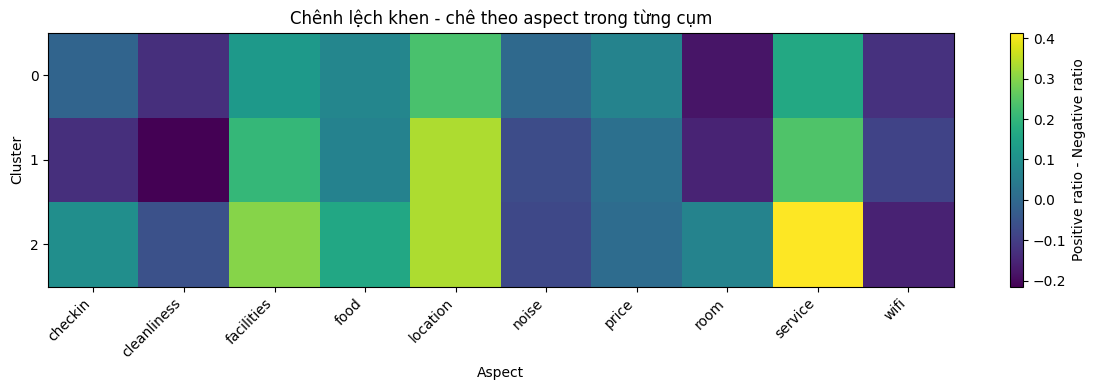

,checkin,cleanliness,facilities,food,location,noise,price,room,service,wifi
cluster,,,,,,,,,,
0,-0.013409,-0.129422,0.122685,0.072644,0.233600,-0.000823,0.066725,-0.179921,0.163416,-0.125681
1,-0.129843,-0.214941,0.203593,0.063987,0.336756,-0.068627,0.017263,-0.152835,0.240996,-0.087429
2,0.094906,-0.060313,0.300192,0.160669,0.336798,-0.077964,0.007702,0.066287,0.413334,-0.154685


In [15]:
# =========================================================
# HEATMAP: POSITIVE - NEGATIVE THEO ASPECT
# =========================================================

balance_cols = [c for c in aspect_balance_full_df.columns if c.endswith("_balance")]

heatmap_df = aspect_balance_full_df[["cluster"] + balance_cols].copy()
heatmap_df = heatmap_df.set_index("cluster")

# Đổi tên cột cho gọn
heatmap_df.columns = [
    c.replace("_balance", "")
    for c in heatmap_df.columns
]

plt.figure(figsize=(12, 4))
plt.imshow(heatmap_df.values, aspect="auto")
plt.xticks(
    range(len(heatmap_df.columns)),
    heatmap_df.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(heatmap_df.index)),
    heatmap_df.index
)
plt.colorbar(label="Positive ratio - Negative ratio")
plt.xlabel("Aspect")
plt.ylabel("Cluster")
plt.title("Chênh lệch khen - chê theo aspect trong từng cụm")
plt.tight_layout()
plt.show()

display(heatmap_df)

In [16]:
# =========================================================
# TOP ĐIỂM MẠNH / ĐIỂM YẾU CỦA TỪNG CỤM
# =========================================================

summary_rows = []

for cluster in heatmap_df.index:
    values = heatmap_df.loc[cluster].sort_values(ascending=False)

    top_strengths = values.head(5)
    top_weaknesses = values.tail(5).sort_values()

    summary_rows.append({
        "cluster": cluster,
        "top_strength_aspects": ", ".join([
            f"{aspect} ({value:.3f})"
            for aspect, value in top_strengths.items()
        ]),
        "top_weak_aspects": ", ".join([
            f"{aspect} ({value:.3f})"
            for aspect, value in top_weaknesses.items()
        ]),
    })

cluster_strength_weakness_df = pd.DataFrame(summary_rows)

display(cluster_strength_weakness_df)

# output_path = TABLE_DIR / "cluster_strength_weakness_by_aspect.csv"
# cluster_strength_weakness_df.to_csv(output_path, index=False, encoding="utf-8-sig")

# print("Saved:", output_path)

,cluster,top_strength_aspects,top_weak_aspects
0,0,"location (0.234), service (0.163), facilities ...","room (-0.180), cleanliness (-0.129), wifi (-0...."
1,1,"location (0.337), service (0.241), facilities ...","cleanliness (-0.215), room (-0.153), checkin (..."
2,2,"service (0.413), location (0.337), facilities ...","wifi (-0.155), noise (-0.078), cleanliness (-0..."
